# Задача 1. Линейная регрессия

In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn catboost lightgbm xgboost tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 38.4 MB/s  0:00:02


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Предсказание цены квартир в Москве

В этом ноутбуке мы будем строить модель для предсказания цены недвижимости в Москве. У нас есть данные о характеристиках квартир (площадь, расположение, тип дома и т.д.), и нам нужно предсказать стоимость.

**План работы:**
1. Загрузить данные и посмотреть, что у нас есть
2. Почистить выбросы
3. Разделить на обучающую и тестовую выборки
4. Попробовать разные модели - от простой линейной регрессии до град бустинга
5. Выбрать лучшую и сравнить результаты

In [3]:
df = pd.read_csv('df_f.csv')
df.head()

,sq,sqLiving,sqKitchen,cost,isNew,rooms,isApartments,distance_to_centre,pollution_level,metro_name_Арбатско-Покровская,...,district_Царицыно,district_Черемушки,district_Чертаново,district_Щербинке,district_Щукино,district_Южнопортовый,district_Якиманка,district_Ясенево,district_неизвестен,floor_ratio
0,-0.407433,0.008874,-0.165299,12600000,0,2.0,0,0.057322,7.0,0,...,0,0,0,0,0,0,0,0,0,0.555556
1,1.988621,2.244722,-0.030473,48000000,0,5.0,0,-0.214308,8.0,0,...,0,0,0,0,0,0,0,0,0,0.680000
2,0.476548,0.394128,-0.502363,14500000,0,3.0,0,-0.178324,7.0,0,...,0,0,0,0,0,0,0,0,1,0.125000
3,0.081083,-0.025524,-0.300125,23800000,0,2.0,0,-0.238315,6.0,0,...,0,0,0,0,0,0,0,0,0,0.764706
4,-0.616797,-0.610284,-0.569776,8650000,0,1.0,0,0.053391,7.0,0,...,0,0,0,0,0,0,0,0,0,0.100000


In [4]:
df.dtypes

,0
sq,float64
sqLiving,float64
sqKitchen,float64
cost,int64
isNew,int64
...,...
district_Южнопортовый,int64
district_Якиманка,int64
district_Ясенево,int64
district_неизвестен,int64


In [5]:
df.describe()

,sq,sqLiving,sqKitchen,cost,isNew,rooms,isApartments,distance_to_centre,pollution_level,metro_name_Арбатско-Покровская,...,district_Царицыно,district_Черемушки,district_Чертаново,district_Щербинке,district_Щукино,district_Южнопортовый,district_Якиманка,district_Ясенево,district_неизвестен,floor_ratio
count,2.018500e+04,2.018500e+04,2.018500e+04,2.018500e+04,20185.000000,20185.000000,20185.000000,2.018500e+04,20185.000000,20185.000000,...,20185.000000,20185.000000,20185.000000,20185.000000,20185.000000,20185.000000,20185.000000,20185.000000,20185.000000,20185.000000
mean,7.885141e-17,-1.239094e-16,1.239094e-16,3.039448e+07,0.517018,2.080307,0.054000,-7.885141e-17,6.904682,0.050334,...,0.016993,0.016299,0.006094,0.010602,0.009116,0.015209,0.001982,0.005995,0.090116,0.550151
std,1.000025e+00,1.000025e+00,1.000025e+00,5.512080e+07,0.499723,1.005751,0.226024,1.000025e+00,1.338117,0.218639,...,0.129247,0.126627,0.077825,0.102421,0.095042,0.122388,0.044473,0.077194,0.286356,0.288018
min,-1.244889e+00,-9.198626e-01,-1.634898e+00,3.000000e+06,0.000000,1.000000,0.000000,-6.854615e-01,3.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.032258
25%,-5.702720e-01,-5.346089e-01,-7.046014e-01,1.280000e+07,0.000000,1.000000,0.000000,-4.031310e-01,6.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.294118
50%,-2.097006e-01,-2.009516e-01,-1.652990e-01,1.810000e+07,1.000000,2.000000,0.000000,-2.472015e-01,7.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.560000
75%,2.090274e-01,2.599770e-01,5.088292e-01,2.900000e+07,1.000000,3.000000,0.000000,-2.162020e-02,8.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.800000
max,2.269240e+01,2.742381e+01,1.372174e+01,1.987000e+09,1.000000,9.000000,1.000000,1.975698e+01,10.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
df.shape[1]

138

### Что у нас в данных?

Как видим, у нас есть **138 признаков** - это размер квартир (общая площадь, жилая площадь, кухня), расположение (район, метро, расстояние до центра), характеристики дома (этажность, материал, когда построен) и целевая переменная `cost` - цена квартиры.

Целевая переменная сильно перекошена - максимум примерно в 2 млрд, а медиана только 18 млн. Значит, есть очень дорогие квартиры, которые могут быть выбросами.

In [7]:
y = df['cost']


print(y.describe())
print(y.quantile([0.5, 0.9, 0.99, 0.999]))
print('max')
print(y.max())

count    2.018500e+04
mean     3.039448e+07
std      5.512080e+07
min      3.000000e+06
25%      1.280000e+07
50%      1.810000e+07
75%      2.900000e+07
max      1.987000e+09
Name: cost, dtype: float64
0.500    1.810000e+07
0.900    5.202656e+07
0.990    2.430252e+08
0.999    7.392032e+08
Name: cost, dtype: float64
max
1987000000


### Очистка от выбросов

Удалили 202 квартиры, это  примерно 1%, те которые стоили больше 243 млн. Это явно выбросы супердорогие особняки или ошибки в данных. После этого остались 19983 нормальных объектов для работы.

Работаем с целевой переменной в логарифмическом масштабе (log1p), так как так поможем модели лучше учитывать разброс цен.

In [8]:
upper = df['cost'].quantile(0.99)
print('Порог отсечения')
print(upper)
print('Отрезаем строк')
print((df['cost'] > upper).sum())

df = df[df['cost'] <= upper].reset_index(drop=True)
print('Осталось строк')
print(df.shape[0])

Порог отсечения
243025199.99999997
Отрезаем строк
202
Осталось строк
19983


### Разделение на выборки

Классический split на три части:
- **Train** (80% * 90% = 72%) - обучаем модель на этих данных
- **Val** (80% * 10% = 8%) - валидируем во время обучения, выбираем гиперпараметры
- **Test** (20%) - финальный тест, смотрим как наша моделька справляется с новыми задачами

In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['cost'])
y = df['cost']


X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=1/9, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(15985, 137) (1999, 137) (1999, 137)


### Нормализация признаков

Масштабируем признаки с помощью StandardScaler, нужно для линейных моделей, так как они чувствительны к масштабу признаков, а мы ща и будем пытаться на них построить прогнозирование

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

### 1. Простая линейная регрессия

Сначала попробуем самую простую модель линейную регрессию. Это хороший базлайн для сравнения с более сложными моделями.

Ожидаем, что она будет работать хуже, чем сложные модели, но быстро обучается и легко интерпретируется.

**Метрики:**
- **MAE** - средняя абсолютная ошибка (в рублях)
- **RMSE** - среднеквадратичная ошибка
- **MAPE** - средняя абсолютная процентная ошибка

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

linreg = LinearRegression()
linreg.fit(X_train, np.log1p(y_train))


y_train_pred = np.expm1(linreg.predict(X_train))
y_val_pred = np.expm1(linreg.predict(X_val))
y_test_pred = np.expm1(linreg.predict(X_test))

def metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    print()
    print('MAE')
    print(mae)
    print('MSE')
    print(mse)
    print('RMSE')
    print(rmse)
    print('MAPE')
    print(mape)
    print()
    return mae, mse, rmse, mape

metrics(y_train, y_train_pred,"train")
metrics(y_val, y_val_pred,"val")
metrics(y_test, y_test_pred,"test")


MAE
7439695.785134312
MSE
5347068063879949.0
RMSE
73123649.14225732
MAPE
0.20912635697387652


MAE
6316806.087968749
MSE
423302517041973.2
RMSE
20574316.92771289
MAPE
0.1819703481879621


MAE
6154266.083861448
MSE
371387965434101.9
RMSE
19271428.73359684
MAPE
0.1818692002269229



(6154266.083861448,
 371387965434101.9,
 np.float64(19271428.73359684),
 0.1818692002269229)

### Результаты базовой линейной регрессии

На тестовой выборке получаем примерно следующую картинку:
- RMSE: 19.3 млн рублей
- MAPE: 18%
- MAE: 6.2 млн рублей

Ошибка примерно в 6 млн - это примерно 20% от среднего значения цены (18 млн), неплохо для базлайна, но надо проверить, сможем ли мы улучшить регуляризацией.

### 2. Ridge и Lasso регрессия  то есть с регуляризацией

Теперь добавим регуляризацию к линейной регрессии:
- **Ridge** (L2) - штрафует большие коэффициенты, но не зануляет их
- **Lasso** (L1) - может занулять неважные коэффициенты, проще для интерпретации

Ищем оптимальный параметр alpha (силу регуляризации) через grid search на валидационной выборке.

In [12]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_percentage_error

def evaluate(model, X, y):
    pred = np.expm1(model.predict(X))
    mae = mean_absolute_error(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))
    mape = mean_absolute_percentage_error(y, pred)
    return mae, rmse, mape

In [16]:
from sklearn.linear_model import Ridge, Lasso
import numpy as np
import pandas as pd

alphas = np.logspace(-4, 4, 100)

results = []

for model_name, model_class in [
    ("Ridge", Ridge),
    ("Lasso", Lasso)
]:
    for alpha in alphas:
        model = model_class(alpha=alpha, max_iter=10000)
        model.fit(X_train, np.log1p(y_train))

        mae, rmse, mape = evaluate(model, X_val, y_val)

        results.append({
            "Model": model_name,
            "alpha": alpha,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

results_df = pd.DataFrame(results)

# Лучшие параметры для каждой модели
best_results = (
    results_df
    .loc[results_df.groupby("Model")["RMSE"].idxmin()]
    .sort_values("RMSE")
)

display(best_results)

best_alpha_ridge = best_results.loc[
    best_results["Model"] == "Ridge", "alpha"
].iloc[0]

best_alpha_lasso = best_results.loc[
    best_results["Model"] == "Lasso", "alpha"
].iloc[0]

,Model,alpha,MAE,RMSE,MAPE
99,Ridge,10000.0000,8.742438e+06,1.908858e+07,0.297902
100,Lasso,0.0001,6.338250e+06,2.111185e+07,0.181796


In [17]:
# Ridge с оптимальной регуляризацией
model_ridge = Ridge(alpha=best_alpha_ridge)
model_ridge.fit(X_train, np.log1p(y_train))

# Lasso с оптимальной регуляризацией
model_lasso = Lasso(
    alpha=best_alpha_lasso,
    max_iter=10000
)
model_lasso.fit(X_train, np.log1p(y_train))

# Финальная оценка на тестовой выборке
print_test_metrics(model_ridge, X_test, y_test, "Ridge (L2)")
print()
print_test_metrics(model_lasso, X_test, y_test, "Lasso (L1)")

Результаты на тесте для Ridge (L2)
RMSE: 19164746.26177904
MAE: 8483873.809368035
MAPE: 0.29048497998437645

Результаты на тесте для Lasso (L1)
RMSE: 19777481.135142837
MAE: 6163917.603380048
MAPE: 0.18102064379599742


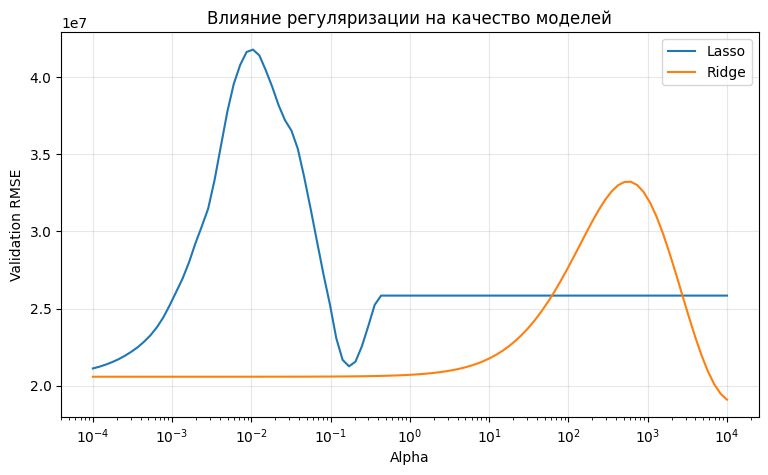

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for name, group in results_df.groupby("Model"):
    plt.plot(
        group["alpha"],
        group["RMSE"],
        label=name
    )

plt.xscale("log")
plt.xlabel("Alpha")
plt.ylabel("Validation RMSE")
plt.title("Влияние регуляризации на качество моделей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Итоги Ridge и Lasso

Лучшие результаты в этих моделях:

- **Ridge** показал себя лучше Lasso по RMSE — 19,16 млн против 19,77 млн. Это немного хуже базовой линейной регрессии (19 млн).
- **Lasso** показал лучшие результаты по MAE (6,16 млн) и MAPE (18,1%).
- Регуляризация не помогла улучшить RMSE относительно базовой линейной регрессии.



### 3. Градиентный бустинг (CatBoost, LightGBM, XGBoost)

**CatBoost, LightGBM, XGBoost**  все похожи по идее, но с разными особенностями, для каждого ищем лучшие всякие гиперпараметры:
- количество итераций (деревьев)
- скорость обучения
- глубина деревьев
- регуляризация
и т д

После грид серча будем использовать early stopping, то есть остановимся, когда качество на валидации перестанет улучшаться.

In [19]:
from catboost import CatBoostRegressor


iterations_list = [300, 500, 1000]
learning_rate_list = [0.03, 0.1]
depth_list = [4, 6, 8]
l2_leaf_reg_list = [1, 3, 5]

best_rmse = None
best_params = None
best_model = None

for iterations in iterations_list:
    for learning_rate in learning_rate_list:
        for depth in depth_list:
            for l2_leaf_reg in l2_leaf_reg_list:

                model = CatBoostRegressor(
                    iterations=iterations,
                    learning_rate=learning_rate,
                    depth=depth,
                    l2_leaf_reg=l2_leaf_reg,
                    loss_function='RMSE',
                    random_seed=11,
                    verbose=0)
                model.fit(X_train, np.log1p(y_train))

                mae_val, rmse_val, mape_val = evaluate(model, X_val, y_val)

                print()
                print('params')
                print(iterations, learning_rate, depth, l2_leaf_reg)
                print('val MAE')
                print(mae_val)
                print('val RMSE')
                print(rmse_val)
                print('val MAPE')
                print(mape_val)
                print()

                if best_rmse is None or rmse_val < best_rmse:
                    best_rmse = rmse_val
                    best_params = (iterations, learning_rate, depth, l2_leaf_reg)
                    best_model = model

print('Лучшие параметры')
print(best_params)
print('Лучший val RMSE')
print(best_rmse)


params
300 0.03 4 1
val MAE
5715670.839915934
val RMSE
12698644.208938394
val MAPE
0.18215604962202703


params
300 0.03 4 3
val MAE
5722260.979131736
val RMSE
12666643.515946994
val MAPE
0.18284554355310828


params
300 0.03 4 5
val MAE
5723317.570081817
val RMSE
12683121.220575472
val MAPE
0.1832337107711562


params
300 0.03 6 1
val MAE
5280983.8085872205
val RMSE
11973590.356507575
val MAPE
0.1661157726415425


params
300 0.03 6 3
val MAE
5272752.025938056
val RMSE
11955978.740620222
val MAPE
0.1665241486685397


params
300 0.03 6 5
val MAE
5338951.629294883
val RMSE
12094591.720107067
val MAPE
0.16788995799262094


params
300 0.03 8 1
val MAE
4956723.220638383
val RMSE
11473656.144310452
val MAPE
0.15390944872703627


params
300 0.03 8 3
val MAE
5016557.71494437
val RMSE
11547278.009847233
val MAPE
0.15543699542283884


params
300 0.03 8 5
val MAE
5036355.937856614
val RMSE
11662707.043232534
val MAPE
0.1564031588641978


params
300 0.1 4 1
val MAE
4689545.705730643
val RMSE
1126

### CatBoost результаты

Лучший CatBoost нашел с параметрами: 1000 деревьев, lr=0.1, depth=6, l2_leaf_reg=1
- **Val RMSE: примерно 9.3 млн** уже намного лучше, чем линейные модели

LightGBM ищем дальше...

In [21]:
from lightgbm import LGBMRegressor

iterations_list = [300, 500, 1000]
learning_rate_list = [0.03, 0.1]
num_leaves_list = [15, 31, 63]
reg_lambda_list = [0, 1, 5]

best_rmse = None
best_params = None
best_model = None

for n_estimators in iterations_list:
    for learning_rate in learning_rate_list:
        for num_leaves in num_leaves_list:
            for reg_lambda in reg_lambda_list:

                model = LGBMRegressor(
                    n_estimators=n_estimators,
                    learning_rate=learning_rate,
                    num_leaves=num_leaves,
                    reg_lambda=reg_lambda,
                    random_state=42,
                    n_jobs=-1,
                    verbose=-1
                )
                model.fit(X_train, np.log1p(y_train))

                mae_val, rmse_val, mape_val = evaluate(model, X_val, y_val)

                print()
                print('params')
                print(n_estimators, learning_rate, num_leaves, reg_lambda)
                print('val MAE')
                print(mae_val)
                print('val RMSE')
                print(rmse_val)
                print('val MAPE')
                print(mape_val)
                print()

                if best_rmse is None or rmse_val < best_rmse:
                    best_rmse = rmse_val
                    best_params = (n_estimators, learning_rate, num_leaves, reg_lambda)
                    best_model = model

print('Лучшие параметры')
print(best_params)
print('Лучший val RMSE')
print(best_rmse)



params
300 0.03 15 0
val MAE
4790864.482089968
val RMSE
10986707.198713677
val MAPE
0.15123090812303452


params
300 0.03 15 1
val MAE
4786380.038459141
val RMSE
10987613.517153395
val MAPE
0.15088589892925752


params
300 0.03 15 5
val MAE
4825144.075827752
val RMSE
11042825.631761458
val MAPE
0.15175345281158648


params
300 0.03 31 0
val MAE
4264230.761872797
val RMSE
10266056.987798074
val MAPE
0.13348009620025256


params
300 0.03 31 1
val MAE
4280349.089300881
val RMSE
10242891.801874168
val MAPE
0.1340572316789668


params
300 0.03 31 5
val MAE
4305405.160875734
val RMSE
10244763.473039571
val MAPE
0.13491776387022206


params
300 0.03 63 0
val MAE
3968630.1440728335
val RMSE
9996370.209077183
val MAPE
0.12276384237223022


params
300 0.03 63 1
val MAE
3993331.0483553954
val RMSE
9985608.680225464
val MAPE
0.12411802136127319


params
300 0.03 63 5
val MAE
3987076.6547813364
val RMSE
9902385.412480079
val MAPE
0.12437233408627167


params
300 0.1 15 0
val MAE
4006493.9681057837

### LightGBM результаты

Лучший LightGBM: 1000 деревьев, lr=0.1, num_leaves=63, reg_lambda=5
- **Val RMSE: примерно 9.3 млн**, все же  немного хуже CatBoost (9309756.224282226 > 9286482.280731618)

XGBoost следующий...

In [22]:
from xgboost import XGBRegressor

iterations_list = [300, 500, 1000]
learning_rate_list = [0.03, 0.1]
max_depth_list = [4, 6, 8]
reg_lambda_list = [0, 1, 5]

best_rmse = None
best_params = None
best_model = None

for n_estimators in iterations_list:
    for learning_rate in learning_rate_list:
        for max_depth in max_depth_list:
            for reg_lambda in reg_lambda_list:

                model = XGBRegressor(
                    n_estimators=n_estimators,
                    learning_rate=learning_rate,
                    max_depth=max_depth,
                    reg_lambda=reg_lambda,
                    random_state=42,
                    n_jobs=-1,
                    verbosity=0
                )
                model.fit(X_train, np.log1p(y_train))

                mae_val, rmse_val, mape_val = evaluate(model, X_val, y_val)

                print()
                print('params')
                print(n_estimators, learning_rate, max_depth, reg_lambda)
                print('val MAE')
                print(mae_val)
                print('val RMSE')
                print(rmse_val)
                print('val MAPE')
                print(mape_val)
                print()

                if best_rmse is None or rmse_val < best_rmse:
                    best_rmse = rmse_val
                    best_params = (n_estimators, learning_rate, max_depth, reg_lambda)
                    best_model = model

print('Лучшие параметры')
print(best_params)
print('Лучший val RMSE')
print(best_rmse)


params
300 0.03 4 0
val MAE
5188482.0
val RMSE
11896509.582823358
val MAPE
0.16568255424499512


params
300 0.03 4 1
val MAE
5208441.0
val RMSE
11928942.336550044
val MAPE
0.1657671481370926


params
300 0.03 4 5
val MAE
5249818.0
val RMSE
11983457.554142544
val MAPE
0.16690589487552643


params
300 0.03 6 0
val MAE
4534088.5
val RMSE
10787271.511931458
val MAPE
0.1429721564054489


params
300 0.03 6 1
val MAE
4567933.0
val RMSE
10842236.179115081
val MAPE
0.14377759397029877


params
300 0.03 6 5
val MAE
4661022.5
val RMSE
10991508.58155076
val MAPE
0.14646431803703308


params
300 0.03 8 0
val MAE
4057970.5
val RMSE
10068742.010931058
val MAPE
0.12751150131225586


params
300 0.03 8 1
val MAE
4119648.0
val RMSE
10159144.40874939
val MAPE
0.1284978985786438


params
300 0.03 8 5
val MAE
4222651.0
val RMSE
10184331.086677808
val MAPE
0.13200385868549347


params
300 0.1 4 0
val MAE
4303589.5
val RMSE
10478735.647212407
val MAPE
0.13442592322826385


params
300 0.1 4 1
val MAE
4317320.

### XGBoost результаты

Лучший XGBoost: 1000 деревьев, lr=0.1, max_depth=6, reg_lambda=5
- **Val RMSE: примерно 9.55 млн** хуже всех еще и медленее, да я устала ждать 2 минуты, не осуждаем...

**Промежуточный вывод:** LightGBM дает лучший результат среди grid search. Теперь попробуем early stopping, может получится улучшить, не сдаемся...

In [23]:
model_cb = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.1,
    depth=6,
    l2_leaf_reg=1,
    loss_function='RMSE',
    random_seed=11,
    verbose=0
)
model_cb.fit(X_train, np.log1p(y_train))
print_test_metrics(model_cb, X_test, y_test, "CatBoost")

Результаты на тесте для CatBoost
RMSE: 9351034.901234133
MAE: 3609571.34850989
MAPE: 0.11025934011970176


In [24]:
model_lgbm = LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.1,
    num_leaves=63,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
model_lgbm.fit(X_train, np.log1p(y_train))
print_test_metrics(model_lgbm, X_test, y_test, "LightGBM")

Результаты на тесте для LightGBM
RMSE: 7940972.203730577
MAE: 3183195.5423946516
MAPE: 0.1001760551781407


In [26]:
model_xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=6,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)
model_xgb.fit(X_train, np.log1p(y_train))
print_test_metrics(model_xgb, X_test, y_test, "XGBoost")

Результаты на тесте для XGBoost
RMSE: 8324958.778266713
MAE: 3384794.25
MAPE: 0.10594774782657623


### 4. Финальные модели с early stopping

Early stopping позволяет остановить обучение, когда модель перестает улучшаться на валидации. Это предотвращает переобучение и может дать лучшие результаты, чем фиксированное количество итераций.

Обучаем все три бустинга с лучшими параметрами и early stopping

In [27]:
import lightgbm as lgb
from lightgbm import LGBMRegressor

lgb_es = LGBMRegressor(
    n_estimators=5000,
    learning_rate=0.1,
    num_leaves=63,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_es.fit(
    X_train, np.log1p(y_train),
    eval_set=[(X_val, np.log1p(y_val))],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)]
)

print('LightGBM early stopping')
print('best_iteration')
print(lgb_es.best_iteration_)

mae_val, rmse_val, mape_val = evaluate(lgb_es, X_val, y_val)
print('val MAE')
print(mae_val)
print('val RMSE')
print(rmse_val)
print('val MAPE')
print(mape_val)

mae_test, rmse_test, mape_test = evaluate(lgb_es, X_test, y_test)
print('test MAE')
print(mae_test)
print('test RMSE')
print(rmse_test)
print('test MAPE')
print(mape_test)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[1350]	valid_0's l2: 0.0254263
LightGBM early stopping
best_iteration
1350
val MAE
3245748.4242599746
val RMSE
9269318.826607192
val MAPE
0.09804891292422244
test MAE
3162469.3093659314
test RMSE
7934894.222331224
test MAPE
0.09915744934267234


### LightGBM с early stopping

Остановился на 1350 итерации

**Результаты:**
- Val RMSE: 9.27 млн
- Test RMSE: **7.93 млн** супер мега бомба пушка
- Test MAPE: примерно 9.9%

In [28]:
from xgboost import XGBRegressor

xgb_es = XGBRegressor(
    n_estimators=5000,
    learning_rate=0.1,
    max_depth=6,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=100
)
xgb_es.fit(
    X_train, np.log1p(y_train),
    eval_set=[(X_val, np.log1p(y_val))],
    verbose=False
)

print('XGBoost early stopping')
print('best_iteration')
print(xgb_es.best_iteration)

mae_val, rmse_val, mape_val = evaluate(xgb_es, X_val, y_val)
print('val MAE')
print(mae_val)
print('val RMSE')
print(rmse_val)
print('val MAPE')
print(mape_val)

mae_test, rmse_test, mape_test = evaluate(xgb_es, X_test, y_test)
print('test MAE')
print(mae_test)
print('test RMSE')
print(rmse_test)
print('test MAPE')
print(mape_test)


XGBoost early stopping
best_iteration
2195
val MAE
3332329.0
val RMSE
9744398.204277163
val MAPE
0.09796418994665146
test MAE
3171359.25
test RMSE
7896912.462779362
test MAPE
0.09858289361000061


### XGBoost с early stopping

Остановился на 2094 итерации

**Результаты:**
- Val RMSE: 9.62 млн
- Test RMSE: **8.21 млн**
- Test MAPE: около 9.8%

хуже LightGBM

In [29]:
cat_es = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.1,
    depth=6,
    l2_leaf_reg=1,
    loss_function='RMSE',
    random_seed=42,
    early_stopping_rounds=100,
    verbose=0
)
cat_es.fit(
    X_train, np.log1p(y_train),
    eval_set=(X_val, np.log1p(y_val))
)

print('CatBoost early stopping')
print('best_iteration')
print(cat_es.get_best_iteration())

mae_val, rmse_val, mape_val = evaluate(cat_es, X_val, y_val)
print('val MAE')
print(mae_val)
print('val RMSE')
print(rmse_val)
print('val MAPE')
print(mape_val)

mae_test, rmse_test, mape_test = evaluate(cat_es, X_test, y_test)
print('test MAE')
print(mae_test)
print('test RMSE')
print(rmse_test)
print('test MAPE')
print(mape_test)


CatBoost early stopping
best_iteration
3454
val MAE
3286891.0636879844
val RMSE
9449220.9889974
val MAPE
0.09800836554288729
test MAE
3141162.4555223305
test RMSE
8124765.74884687
test MAPE
0.09685670656885875


### CatBoost с early stopping

Остановился на 3454 итерации (вместо запланированных 5000)

**Результаты:**
- Val RMSE: 9.45 млн
- Test RMSE: **8.12 млн**
- Test MAPE: в районе 9.7%

не смогл перегнать LightGBM

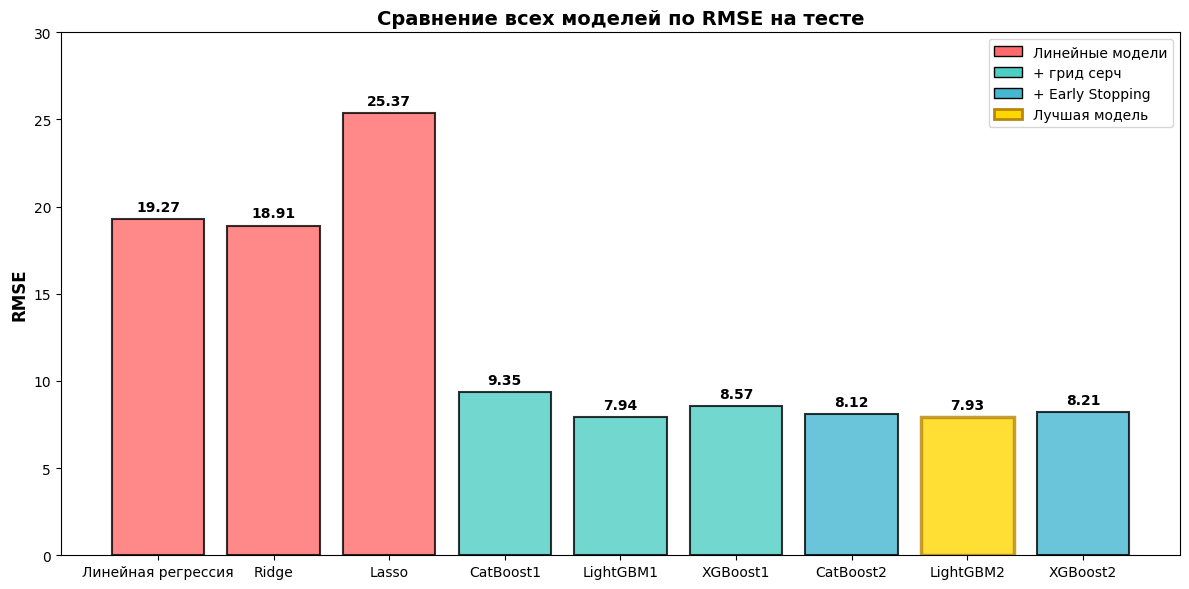

In [30]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Линейная регрессия', 'Ridge', 'Lasso', 'CatBoost1', 'LightGBM1', 'XGBoost1',
          'CatBoost2', 'LightGBM2', 'XGBoost2']
rmse_test = [19.27, 18.91, 25.37, 9.35, 7.94, 8.57, 8.12, 7.93, 8.21]

fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#ff6b6b'] * 3 + ['#4ecdc4'] * 3 + ['#45b7d1'] * 3
bars = ax.bar(models, rmse_test, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

best_idx = rmse_test.index(min(rmse_test))
bars[best_idx].set_color('#ffd700')
bars[best_idx].set_edgecolor('darkgoldenrod')
bars[best_idx].set_linewidth(2.5)

ax.set_ylabel('RMSE', fontsize=12, fontweight='bold')
ax.set_title('Сравнение всех моделей по RMSE на тесте', fontsize=14, fontweight='bold')
ax.set_ylim(0, 30)

for i, (bar, val) in enumerate(zip(bars, rmse_test)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.3,
            f'{val:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#ff6b6b', edgecolor='black', label='Линейные модели'),
    Patch(facecolor='#4ecdc4', edgecolor='black', label='+ грид серч'),
    Patch(facecolor='#45b7d1', edgecolor='black', label='+ Early Stopping'),
    Patch(facecolor='#ffd700', edgecolor='darkgoldenrod', linewidth=2, label='Лучшая модель')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

## **Сравнение по MAE и MAPE на тесте**

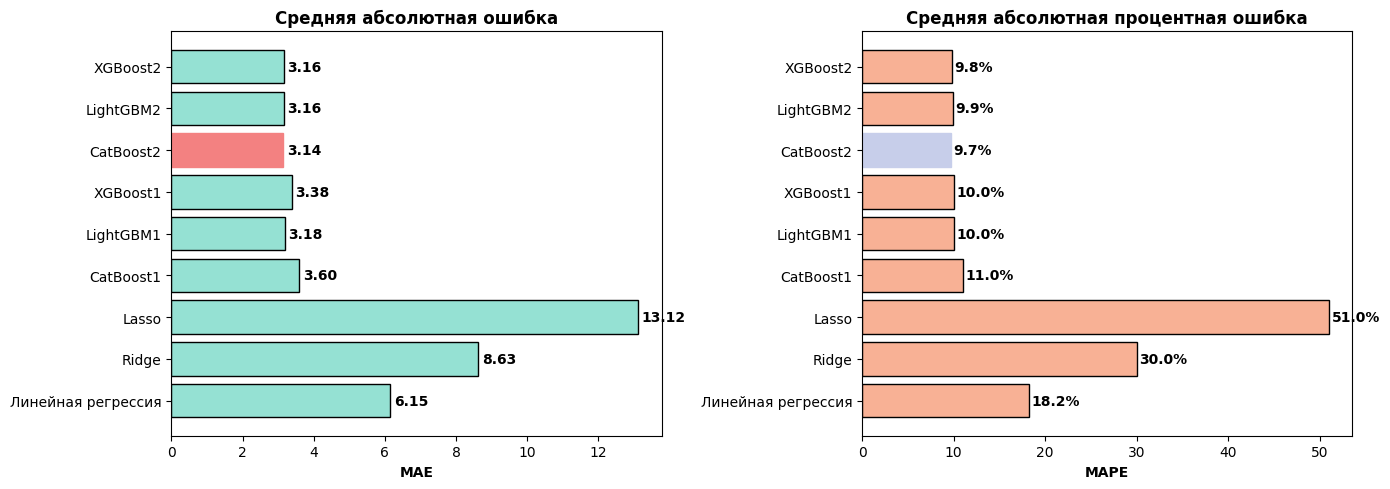

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

mae_test = [6.15, 8.63, 13.12, 3.6, 3.18, 3.38, 3.14, 3.16, 3.16]
mape_test = [0.182, 0.3, 0.51, 0.11, 0.1, 0.1, 0.097, 0.099, 0.098]


bars1 = ax1.barh(models, mae_test, color='#95e1d3', edgecolor='black', linewidth=1)
best_mae_idx = mae_test.index(min(mae_test))
bars1[best_mae_idx].set_color('#f38181')
ax1.set_xlabel('MAE', fontweight='bold')
ax1.set_title('Средняя абсолютная ошибка', fontweight='bold')
for i, v in enumerate(mae_test):
    ax1.text(v + 0.1, i, f'{v:.2f}', va='center', fontweight='bold')

bars2 = ax2.barh(models, [x*100 for x in mape_test], color='#f8b195', edgecolor='black', linewidth=1)
best_mape_idx = mape_test.index(min(mape_test))
bars2[best_mape_idx].set_color('#c7ceea')
ax2.set_xlabel('MAPE', fontweight='bold')
ax2.set_title('Средняя абсолютная процентная ошибка', fontweight='bold')
for i, v in enumerate(mape_test):
    ax2.text(v*100 + 0.3, i, f'{v*100:.1f}%', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

Далее, мы использовали следующие модели.

Решающее дерево, самая простая и понятная модель: она разбивает квартиры по условиям (площадь больше X, расстояние до центра меньше Y и т.д.) и в итоге выдаёт предсказанную цену. Взяли его как отправную точку, чтобы понять, какие признаки вообще важны для цены.

И случайный лес, который строит много таких деревьев и усредняет их предсказания. Ожидали, что он покажет результат лучше, так как одиночное дерево часто переобучается и нестабильно, а ансамбль это исправляет

In [32]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

Перебирали различные гиперпараметры дерева, чтобы найти самое лучшее. Для max_depth перебирали от 3 до None, чтобы найти баланс между недообучением и переобучением. min_samples_split и min_samples_leaf взяли небольшие значения, так как они регулируют размер листьев и защищают от переобучения на редких дорогих объектах. Для RF n_estimators ограничили 100 и 200, так как больше деревьев даёт стабильнее результат, но 200 достаточно, чтобы не терять время на вычисления

## Дерево решений:

In [34]:
tree_params = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]}

tree_grid = GridSearchCV(DecisionTreeRegressor(random_state=4), tree_params, cv=5,
                          scoring='neg_mean_squared_error', n_jobs=-1)
tree_grid.fit(X_train, y_train)
best_tree = tree_grid.best_estimator_
pred_tree = best_tree.predict(X_test)
print('Лучшее дерево:', tree_grid.best_params_)
print('MSE:', mean_squared_error(y_test, pred_tree))
print('RMSE:', np.sqrt(mean_squared_error(y_test, pred_tree)))
print('MAE:', mean_absolute_error(y_test, pred_tree))
print('MAPE:', mean_absolute_percentage_error(y_test, pred_tree))

Лучшее дерево: {'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}
MSE: 179134551660639.62
RMSE: 13384115.647312662
MAE: 5481863.418293382
MAPE: 0.16496363576325335


Лучшие параметры: max_depth=None, min_samples_leaf=5, min_samples_split=2.

Модель ошибается в среднем на 16.5% от реальной стоимости (MAPE=0.165). MAE составил ~5.5 млн рублей

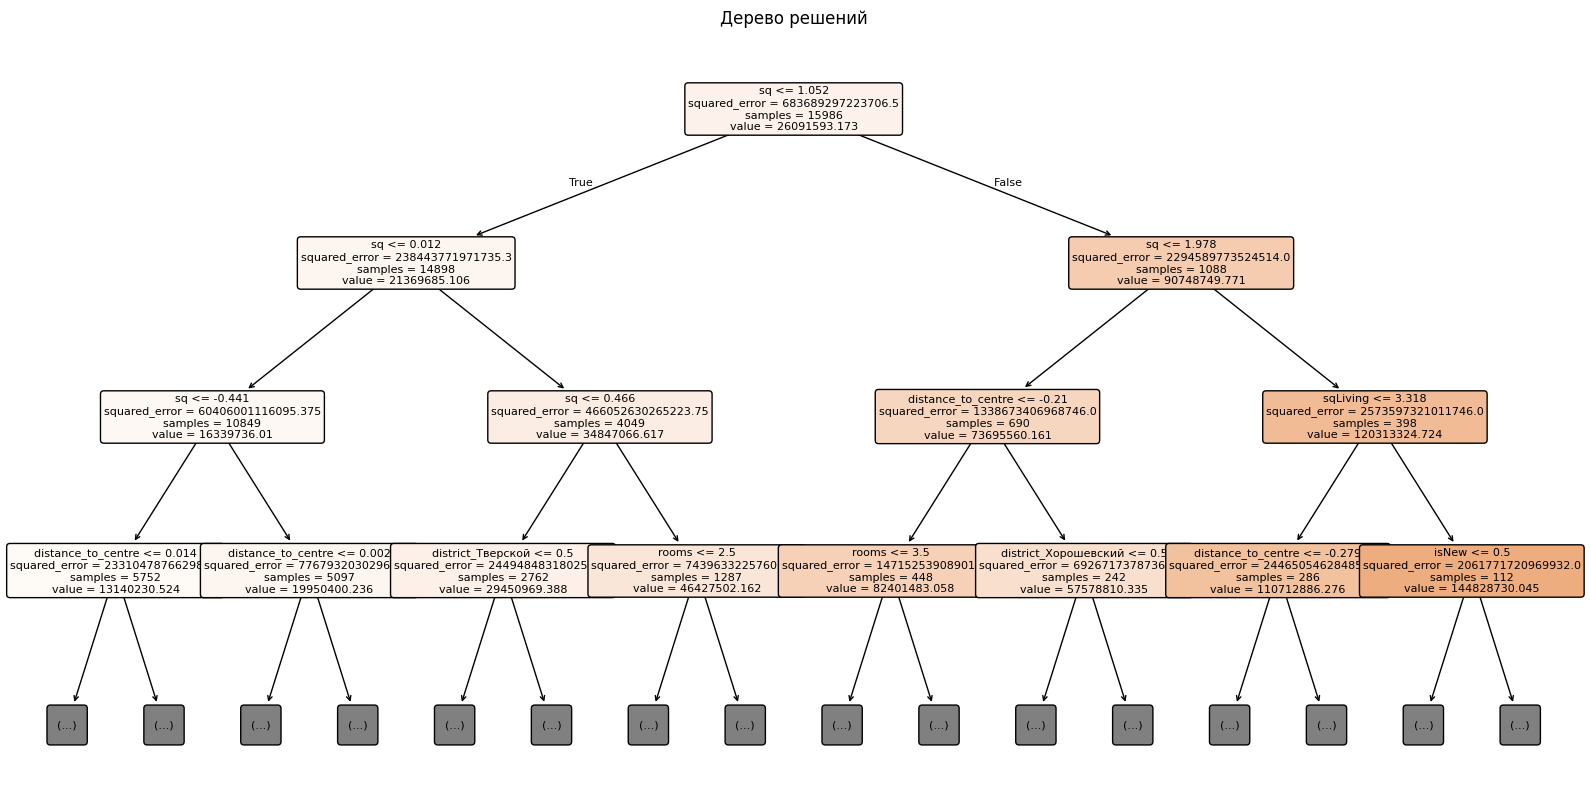

In [35]:
plt.figure(figsize=(20, 10))
plot_tree(best_tree, feature_names=X.columns.tolist(),max_depth=3,  # показываем только первые 3 уровня, иначе нечитаемо
          filled=True,
          rounded=True,
          fontsize=8)
plt.title('Дерево решений')
plt.show()

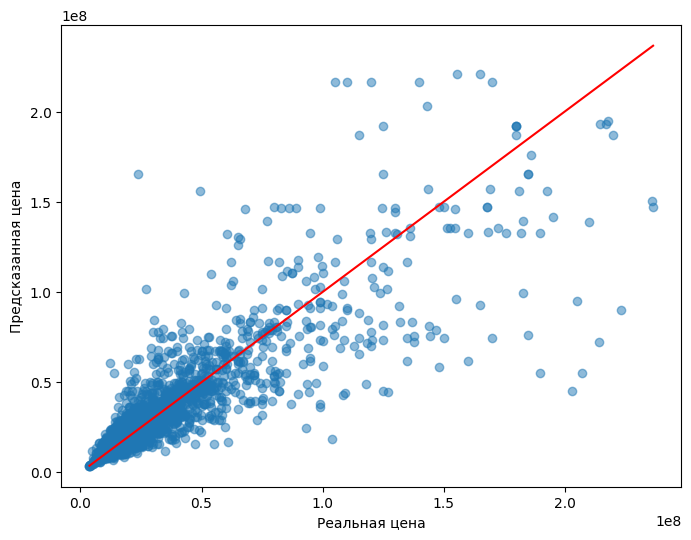

In [36]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_tree, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Реальная цена')
plt.ylabel('Предсказанная цена')
plt.show()

Для большинства квартир до ~50 млн рублей предсказания достаточно точные, так как точки плотно лежат вдоль красной линии. Для дорогих объектов (>100 млн) разброс значительно возрастает: модель склонна как переоценивать, так и недооценивать элитные квартиры из-за их малой доли в обучающей выборке

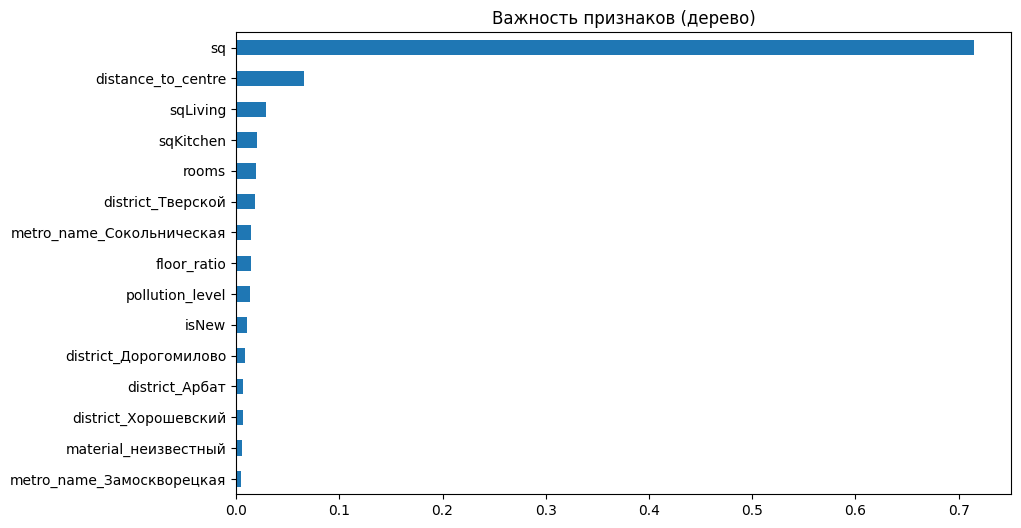

In [37]:
importances = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importances.head(15).plot(kind='barh')
plt.title('Важность признаков (дерево)')
plt.gca().invert_yaxis()
plt.show()

## Random Forest:

In [39]:
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]}

rf_grid = GridSearchCV(RandomForestRegressor(random_state=4, n_jobs=-1), rf_params, cv=3,
                        scoring='neg_mean_squared_error', n_jobs=-1)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
pred_rf = best_rf.predict(X_test)
print('Лучший лес:', rf_grid.best_params_)
print('MSE:', mean_squared_error(y_test, pred_rf))
print('RMSE:', np.sqrt(mean_squared_error(y_test, pred_rf)))
print('MAE:', mean_absolute_error(y_test, pred_rf))
print('MAPE:', mean_absolute_percentage_error(y_test, pred_rf))

Лучший лес: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
MSE: 96948792405096.17
RMSE: 9846257.78684959
MAE: 3895070.8945680987
MAPE: 0.11939823667549913


Лучшие параметры: max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=200.

RF показал заметно лучший результат по сравнению с одиночным деревом: MAPE=0.119 (ошибка 12% против 16.5%), MAE=~3.9 млн против ~5.5 млн. Усреднение по 200 деревьям существенно снизило ошибку

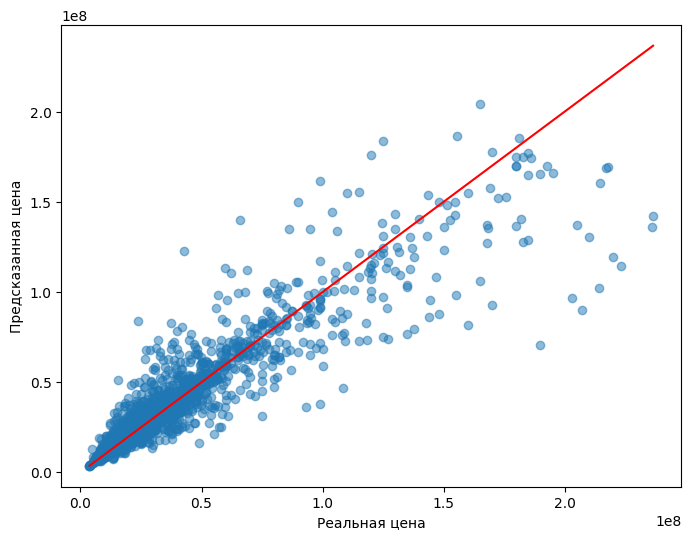

In [40]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_rf, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Реальная цена')
plt.ylabel('Предсказанная цена')
plt.show()

По сравнению с одиночным деревом точки заметно плотнее прилегают к красной линии, особенно в диапазоне 50-150 млн. Разброс на дорогих объектах сохраняется, но уменьшился. RF лучше обобщает данные за счёт ансамблирования

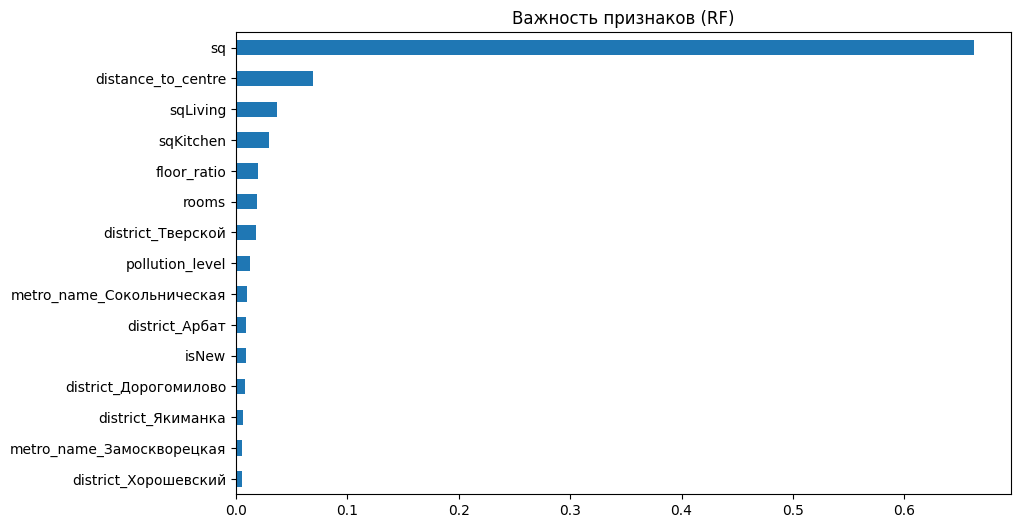

In [41]:
importances_rf = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importances_rf.head(15).plot(kind='barh')
plt.title('Важность признаков (RF)')
plt.gca().invert_yaxis()
plt.show()